# Can we predict the type of a furniture item from its specifications?

**Direction 21 - Furniture · Task type: classification**
Team: Sultanbek Zhumagaliev, Tamerlan Yessimov

**Question.** Can the type of a furniture item (sofa, armchair, chair, bed, wardrobe, chest of drawers, desk, coffee table, TV stand) be predicted from its structured specifications: width, depth, height, materials, colour and price?

**Why it matters.** Marketplaces receive thousands of listings. Sellers fill in the dimensions, but they often put the item in the wrong category. A model that predicts the type from the specs can flag listings whose category disagrees with their numbers. The analysis also shows which specifications separate similar types (wardrobe vs chest of drawers, chair vs armchair) and prepares the ground for recognising furniture type from product photos.

### Contents
1. Question, data and data ethics
2. Data preparation and exploration (cleaning, leakage check, exploration)
3. Modelling workflow (split, pipeline, baseline, three Week 3-4 models, cross-validation)
4. Results and error analysis (metric, fair comparison, confusion matrix, where the model fails)
5. Conclusions and limitations
6. Contributions and AI tools

## 1. Question, data and data ethics

### 1.1 Source and collection
* **Source:** the online store [mebel.kz](https://mebel.kz/) (TOO "Mebel Group KZ", Almaty). The full data card is in `DATA_CARD.md`.
* **How we collected it:** `scraper/collect_mebel.py`:
  1. reads the public sitemap `https://mebel.kz/sitemap.almaty.xml`;
  2. keeps the product URLs whose address looks like one of the nine furniture types;
  3. samples at most 700 per type (seed 42);
  4. downloads each product page;
  5. stores the schema.org JSON-LD product block (name, category, price), the breadcrumbs, the overall size block and the whole specification table in `data/raw/mebel_raw.jsonl`.

  `scraper/build_dataset.py` then turns these raw records into `data/processed/furniture.csv`.
* **One row = one product listing** (one model in one colour/fabric) on mebel.kz.
* **Target:** the store's own category for the product, mapped to our nine types with an explicit dictionary (`CATEGORY_TO_TYPE` in `build_dataset.py`).

### 1.2 How we checked the source
* We read `robots.txt`. It allows `/product/` pages, and we did not request anything it disallows (`/order`, `/terms`, `/data`, ...).
* We compared several scraped rows by hand with the live pages (sizes, price, materials). The automatic checks are in section 2.1.
* The JSON-LD price matches the price shown on the page. The sizes come from the "Размеры" block that customers see.
* While checking, we found that the first version of the size parser missed two page layouts. We fixed it and downloaded the affected pages again (logged in `collection_log.json`).

### 1.3 Data ethics
* **Only public catalogue data.** No accounts or logins were used, and there are no reviews, customer names or other personal data. The shop publishes these prices and specs for anyone to read.
* **Polite collection.** At most 2 connections at a time, at least 0.7 s between requests, and a User-Agent that says this is a student research scraper. Each page was downloaded once and saved as structured JSON, so the analysis never touches the website again.
* **Purpose.** Education and research only. The data is not re-published as a product.

### 1.4 What is missing compared to the task description
The task lists **weight** as a feature. mebel.kz does not publish product weight on its product pages: we checked the page text and the embedded page data for every type. So weight is **not** in our data. This is listed again in the limitations.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
TYPES = ["sofa", "armchair", "chair", "bed", "wardrobe", "chest_of_drawers", "desk", "coffee_table", "tv_stand"]

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.3


In [2]:
# When and how much did we collect?
log = json.loads(Path("data/raw/collection_log.json").read_text())
raw = [json.loads(line) for line in open("data/raw/mebel_raw.jsonl")]
dates = sorted(r["scraped_at"] for r in raw)
print("Source:                       ", log["source"])
print("Product URLs in sitemap:      ", log["products_in_sitemap"])
print("Candidate URLs (9 types):     ", log["candidate_urls"])
print("After cap of", log["cap_per_type"], "per type:     ", log["candidate_urls_after_cap"])
print("Raw records saved:            ", len(raw))
print("Collected between (UTC):      ", dates[0], "and", dates[-1])
print("Politeness:                   ", log["parallel_connections"], "connections,", log["min_seconds_between_requests"], "s between requests")
print("Re-downloads after parser fix:", log.get("refetches"))

Source:                        https://mebel.kz/
Product URLs in sitemap:       9019
Candidate URLs (9 types):      6000
After cap of 700 per type:      4630
Raw records saved:             4630
Collected between (UTC):       2026-10-07T11:46:39+00:00 and 2026-10-07T13:16:58+00:00
Politeness:                    2 connections, 0.7 s between requests
Re-downloads after parser fix: [{'finished_utc': '2026-10-07T13:16:58+00:00', 'pages_refetched': 520, 'now_complete': 353}]


In [3]:
# One raw record, as it was saved (long text shortened)
example = dict(raw[len(raw) // 2])
example["product"] = {k: (v[:80] + "...") if isinstance(v, str) and len(v) > 80 else v for k, v in example["product"].items()}
print(json.dumps(example, ensure_ascii=False, indent=1)[:2500])

{
 "url": "https://mebel.kz/product/krovat-nordik-160-wood-grey",
 "scraped_at": "2026-10-07T12:28:04+00:00",
 "product": {
  "name": "Кровать Нордик 160 Натуральный Серый",
  "sku": "190469",
  "category": "Кровати",
  "color": "Бежевый",
  "description": "Кровать Нордик 160 Натуральный Серый напрямую от производителя в интернет-магази...",
  "price": "183670.00",
  "currency": "KZT",
  "availability": "https://schema.org/InStock"
 },
 "breadcrumbs": [
  "🏠 Интернет-магазин mebel.kz",
  "🛏️ Кровати и матрасы",
  "🛏️ Кровати",
  "🛏️ Кровать Нордик 160 Натуральный Серый"
 ],
 "dimensions": {
  "Длина": "203",
  "Ширина": "165",
  "Высота": "98"
 },
 "specs": {
  "Материал корпуса": "ЛДСП 16 мм",
  "Материал изголовья": "ЛДСП 16 мм",
  "Материал ножек (опор)": "деревянные (сращенный массив)",
  "Подъемный механизм": "без механизма",
  "Наличие ящика для белья": "без ящика для белья",
  "Опоры": "Нордик 1 Древесный (Опора массив ВС 001 древесный 250мм)",
  "Основание кровати": "ортопедиче

In [4]:
df = pd.read_csv("data/processed/furniture.csv")
print(df.shape)
df.head()

(3961, 14)


,url,scraped_at,sku,name,site_category,series,furniture_type,width_cm,depth_cm,height_cm,price_kzt,materials,main_color,n_spec_fields
0,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264693,Детская кровать Анджи 80 Вельвет Голубой,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,light_blue,19
1,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264632,Детская кровать Анджи 80 Вельвет Мятный,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,green,19
2,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264689,Детская кровать Анджи 80 Вельвет Оливковый,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,olive,19
3,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264665,Детская кровать Анджи 80 Вельвет Красный,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,red,19
4,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,268013,Детская кровать Анджи 80 Вельвет Бежевый,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,beige,19


### 1.5 Fields of the processed table

| Column | Meaning | Used as input? |
|---|---|---|
| `url`, `sku`, `name` | product address, store code, product name | **no** - identifiers; the name contains the type ("Кровать ...") |
| `site_category` | the store's category, e.g. "Шкафы распашные" | **no** - this *is* the answer |
| `furniture_type` | our target, one of the nine types | target |
| `series` | product series (e.g. "Леванте"); colour variants share it | **no** - used only to group rows in cross-validation |
| `width_cm`, `depth_cm`, `height_cm` | outer size; the site writes "Длина x Ширина x Высота", which we read as width x depth x height | yes |
| `price_kzt` | price in tenge on the collection date | yes |
| `materials` | material words found in all "Материал ..." and "Каркас" fields, normalised to tokens like `chipboard`, `mdf`, `fabric` | yes |
| `main_color` | first colour in the "Цвет" field, translated | yes |
| `n_spec_fields` | how many spec fields the page has | **no** - kept to show a leak (2.3) |
| `scraped_at` | collection date | no |

## 2. Data preparation and exploration

### 2.1 Cleaning
`build_dataset.py` has already dropped two kinds of rows: products whose category is not one of our nine types (sofa modules, office chairs, nightstands, ...), and products without all three sizes or without a price. Here we check that the remaining values make physical sense.

In [5]:
num_cols = ["width_cm", "depth_cm", "height_cm", "price_kzt"]
df[num_cols].describe().round(1)

,width_cm,depth_cm,height_cm,price_kzt
count,3961.0,3961.0,3961.0,3961.0
mean,139.9,78.6,103.4,293156.4
std,66.0,48.7,55.2,230622.5
min,25.0,23.0,19.9,30550.0
25%,85.0,46.0,76.0,153050.0
50%,137.0,55.0,85.0,229610.0
75%,203.0,96.0,102.0,375070.0
max,421.0,320.0,300.0,2284860.0


In [6]:
n0 = len(df)
steps = {}

# 1. Impossible or broken sizes: below 10 cm or above 5 m on any side
sizes = df[["width_cm", "depth_cm", "height_cm"]]
bad_size = (sizes < 10).any(axis=1) | (sizes > 500).any(axis=1)
steps["size < 10 cm or > 500 cm"] = int(bad_size.sum())
df = df[~bad_size]

# 2. Prices that cannot be a real furniture price (below 5,000 tenge)
bad_price = df["price_kzt"] < 5_000
steps["price < 5,000 KZT"] = int(bad_price.sum())
df = df[~bad_price]

# 3. Exact duplicates of the same URL (should be none)
dup = df.duplicated("url")
steps["duplicate URL"] = int(dup.sum())
df = df[~dup]

# 4. Missing colour gets its own value instead of dropping the row
steps["missing colour -> 'unknown' (kept)"] = int(df["main_color"].isna().sum())
df["main_color"] = df["main_color"].fillna("unknown")
df["materials"] = df["materials"].fillna("")
steps["no material found -> all material flags 0 (kept)"] = int((df["materials"] == "").sum())

df = df.reset_index(drop=True)
print(pd.Series(steps, name="rows affected").to_string())
print(f"\nrows: {n0} -> {len(df)}")

size < 10 cm or > 500 cm                            0
price < 5,000 KZT                                   0
duplicate URL                                       0
missing colour -> 'unknown' (kept)                  5
no material found -> all material flags 0 (kept)    7

rows: 3961 -> 3961


In [7]:
# Same specs and same type in different listings = colour variants of one model.
# Same specs but a *different* type would be label noise. How common is each?
feat = ["width_cm", "depth_cm", "height_cm", "price_kzt", "materials"]
same_specs = df.groupby(feat)["furniture_type"].agg(["size", "nunique"])
print("rows whose specs (size, price, materials) also appear in another row:", int(same_specs.loc[same_specs["size"] > 1, "size"].sum()))
print("spec combinations that carry more than one type label:", int((same_specs["nunique"] > 1).sum()))
per_series = df.groupby("series").size()
print(f"series: {len(per_series)}, listings per series - median {per_series.median():.0f}, max {per_series.max()}")

rows whose specs (size, price, materials) also appear in another row: 3162
spec combinations that carry more than one type label: 0
series: 512, listings per series - median 3, max 178


### 2.2 Class balance

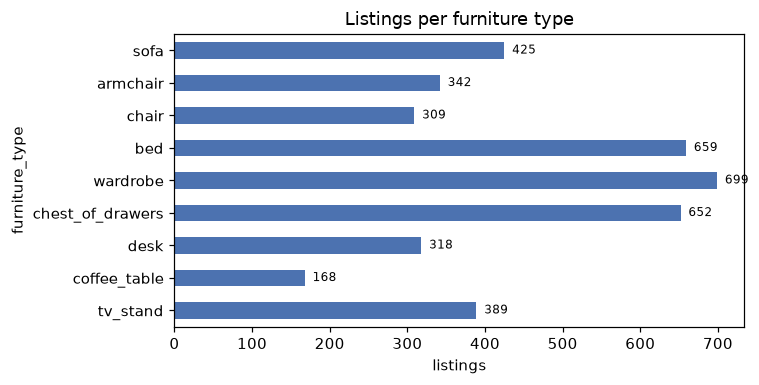

furniture_type
sofa                0.107
armchair            0.086
chair               0.078
bed                 0.166
wardrobe            0.176
chest_of_drawers    0.165
desk                0.080
coffee_table        0.042
tv_stand            0.098


In [8]:
counts = df["furniture_type"].value_counts().reindex(TYPES)
ax = counts.plot.barh(color="#4C72B0", figsize=(7, 3.6))
ax.invert_yaxis(); ax.set_xlabel("listings"); ax.set_title("Listings per furniture type")
for i, v in enumerate(counts):
    ax.text(v + 10, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()
print((counts / counts.sum()).round(3).to_string())

The classes are **imbalanced**. Plain accuracy would reward a model that is good at the large classes and ignores the small ones, so our main metric is **macro-F1**: the F1 score of every class averaged with equal weight. A model can only score high if it recognises coffee tables and desks as well as wardrobes and beds.

### 2.3 Leakage check
Leakage means an input that would not be available in the real use case, or that is the answer in disguise. Our use case: a seller has typed in the size, price, materials and colour, and we want to check the category they chose. We checked three possible leaks.

**(a) Text fields contain the answer.** The product name usually starts with the type word ("Кровать ...", "Комод ..."), and the URL, description, breadcrumbs and `site_category` say it directly.

In [9]:
type_words = {"sofa": "диван", "armchair": "кресл", "chair": "стул", "bed": "кроват", "wardrobe": "шкаф",
              "chest_of_drawers": "комод", "desk": "стол", "coffee_table": "стол", "tv_stand": "тумб"}
hit = df.apply(lambda r: type_words[r["furniture_type"]] in str(r["name"]).lower(), axis=1)
print(f"Product names that contain their own type word: {hit.mean():.1%}")
print(hit.groupby(df["furniture_type"]).mean().reindex(TYPES).round(3).to_string())
print("-> name, url, description, breadcrumbs and site_category are NOT used as inputs.")

Product names that contain their own type word: 92.9%
furniture_type
sofa                1.000
armchair            1.000
chair               0.994
bed                 1.000
wardrobe            1.000
chest_of_drawers    0.598
desk                0.947
coffee_table        1.000
tv_stand            1.000
-> name, url, description, breadcrumbs and site_category are NOT used as inputs.


**(b) Which spec fields a page has gives the type away.** Only beds have "Спальное место"/"Основание кровати", only sofas have "Механизм трансформации", and only wardrobes have "Дверная система". If we turned every spec field into an input, the model would only learn which fields are present. Below we prove it: a small decision tree that sees *only* which spec fields are present (no numbers at all) already reaches a macro-F1 far above the baseline. That score says nothing about our question. So we only use the fields the question allows: sizes, price, colour, and material *values* pooled over all material fields, so that a field name such as "Материал изголовья" (headboard material) cannot leak.

In [10]:
keys_by_url = {r["url"]: set(r["specs"]) for r in raw}
key_counts = pd.Series([k for u in df["url"] for k in keys_by_url[u]]).value_counts()
common_keys = key_counts[key_counts >= 30].index
X_keys = pd.DataFrame([[k in keys_by_url[u] for k in common_keys] for u in df["url"]], columns=common_keys, dtype=int)

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
leak = cross_validate(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), X_keys, df["furniture_type"],
                      groups=df["series"], cv=group_cv, scoring="f1_macro")
print(f"{len(common_keys)} 'page has this spec field' flags only -> macro-F1 = {leak['test_score'].mean():.3f}")

tree_keys = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(X_keys, df["furniture_type"])
print("Fields the tree uses most:", pd.Series(tree_keys.feature_importances_, index=common_keys).nlargest(6).round(3).to_dict())

leak_n = cross_validate(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), df[["n_spec_fields"]], df["furniture_type"],
                        groups=df["series"], cv=group_cv, scoring="f1_macro")
print(f"Only the NUMBER of spec fields -> macro-F1 = {leak_n['test_score'].mean():.3f}  (also excluded)")

63 'page has this spec field' flags only -> macro-F1 = 0.863
Fields the tree uses most: {'Основание кровати': 0.22, 'Дверная система': 0.206, 'Материал столешницы': 0.164, 'Материал корпуса': 0.137, 'Складной': 0.106, 'Расположение': 0.097}


Only the NUMBER of spec fields -> macro-F1 = 0.179  (also excluded)


**(c) Colour variants of the same model.** The store lists one model in many colours as separate products (same series, same size, often the same price). If one colour lands in the training folds and another in the validation fold, the model only has to remember the model, not understand furniture. So **every split in this notebook is grouped by `series`**: all variants of a series are either in training or in validation. Section 3.4 measures how much an ungrouped split would have inflated the score.

### 2.4 Exploration
Which specifications separate the types? We start with the sizes and the price.

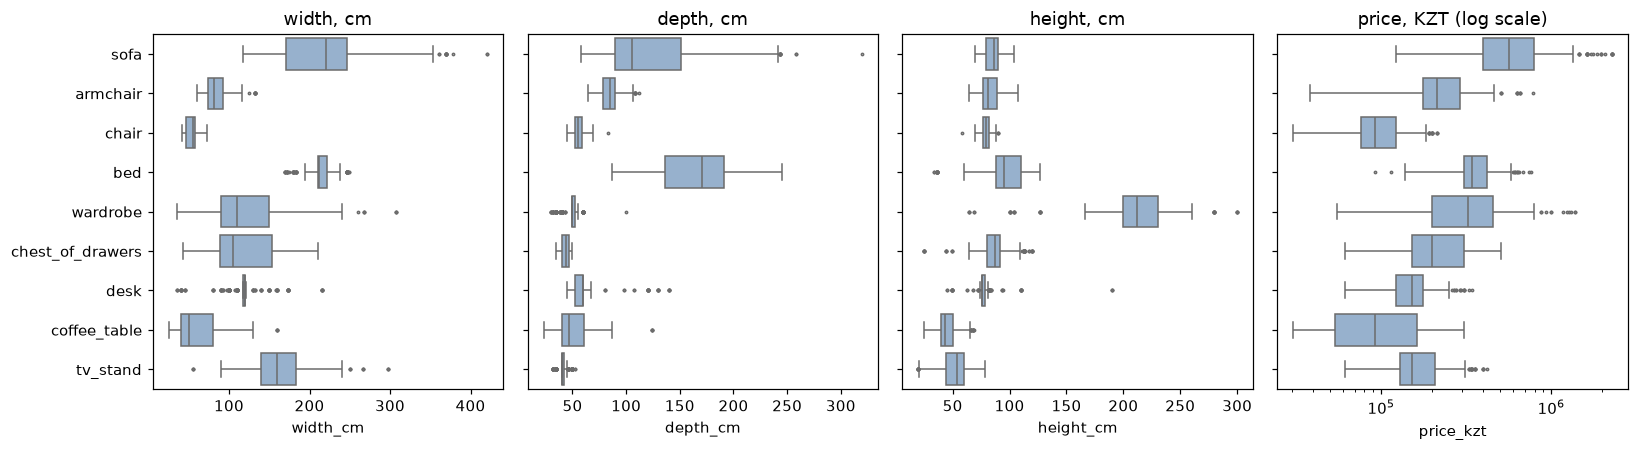

,width_cm,depth_cm,height_cm,price_kzt
furniture_type,,,,
sofa,220.0,105.0,86.0,566470.0
armchair,81.0,85.0,81.0,214300.0
chair,55.0,55.0,79.0,91800.0
bed,212.0,171.0,95.0,344450.0
wardrobe,110.0,50.0,212.0,324540.0
chest_of_drawers,105.0,44.0,87.0,199750.0
desk,120.0,60.0,76.0,153050.0
coffee_table,50.0,47.0,43.0,91800.0
tv_stand,160.0,40.0,54.0,153050.0


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
for ax, col in zip(axes, ["width_cm", "depth_cm", "height_cm", "price_kzt"]):
    sns.boxplot(data=df, y="furniture_type", x=col, order=TYPES, ax=ax, fliersize=1.5, color="#8EB1D6")
    ax.set_ylabel("")
    if col == "price_kzt":
        ax.set_xscale("log")
axes[0].set_title("width, cm"); axes[1].set_title("depth, cm"); axes[2].set_title("height, cm"); axes[3].set_title("price, KZT (log scale)")
plt.tight_layout(); plt.show()
df.groupby("furniture_type")[["width_cm", "depth_cm", "height_cm", "price_kzt"]].median().reindex(TYPES).round(0)

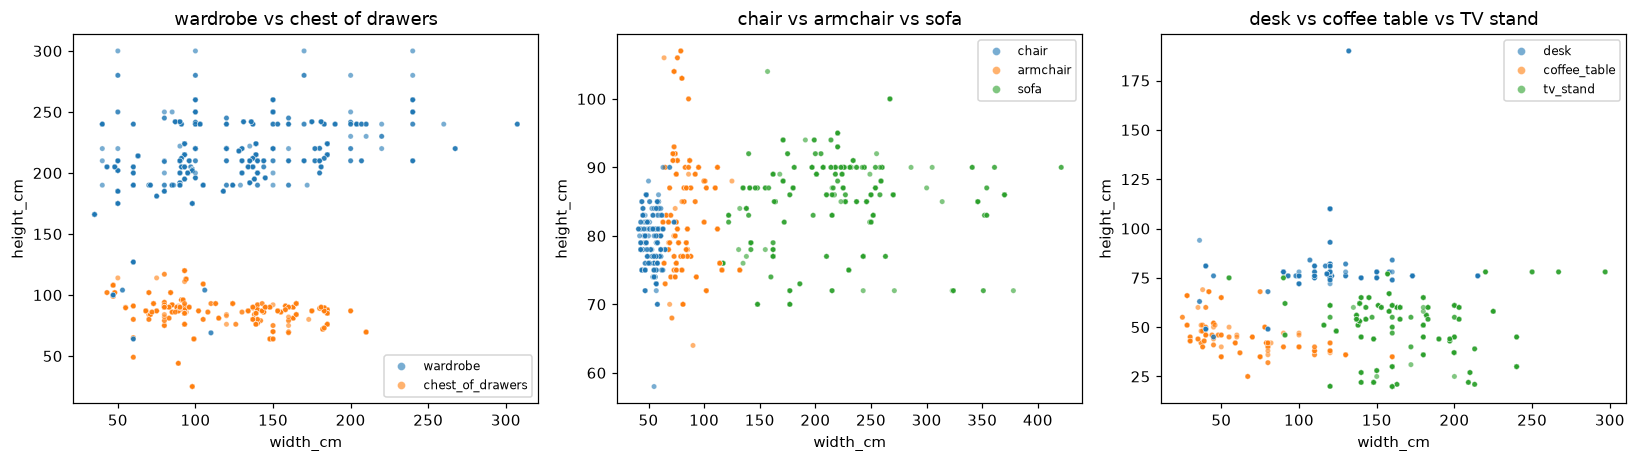

In [12]:
# The three groups of look-alikes from the question
lookalikes = {
    "wardrobe vs chest of drawers": ["wardrobe", "chest_of_drawers"],
    "chair vs armchair vs sofa": ["chair", "armchair", "sofa"],
    "desk vs coffee table vs TV stand": ["desk", "coffee_table", "tv_stand"],
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (title, group) in zip(axes, lookalikes.items()):
    sub = df[df["furniture_type"].isin(group)]
    sns.scatterplot(data=sub, x="width_cm", y="height_cm", hue="furniture_type", hue_order=group, s=12, alpha=0.6, ax=ax)
    ax.set_title(title); ax.legend(fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.show()

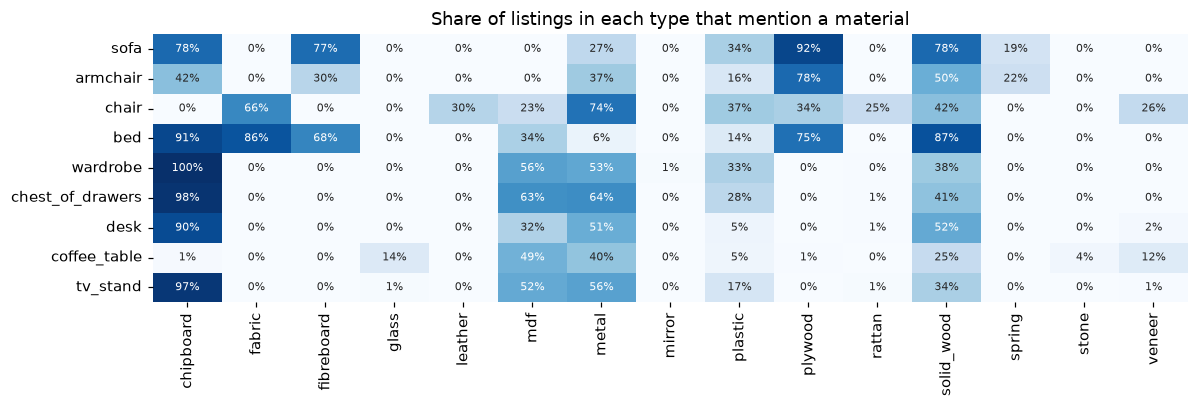

In [13]:
mat = df["materials"].str.get_dummies(sep="|")
share = mat.groupby(df["furniture_type"]).mean().reindex(TYPES)
plt.figure(figsize=(11, 3.8))
sns.heatmap(share, annot=True, fmt=".0%", cmap="Blues", cbar=False, annot_kws={"fontsize": 7})
plt.title("Share of listings in each type that mention a material"); plt.ylabel(""); plt.tight_layout(); plt.show()

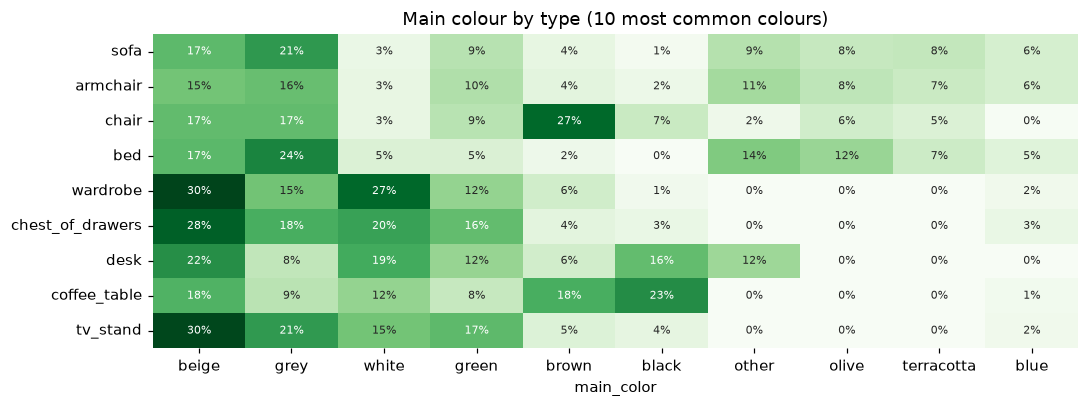

In [14]:
col_share = pd.crosstab(df["furniture_type"], df["main_color"], normalize="index").reindex(TYPES)
col_share = col_share[col_share.mean().sort_values(ascending=False).index[:10]]
plt.figure(figsize=(10, 3.8))
sns.heatmap(col_share, annot=True, fmt=".0%", cmap="Greens", cbar=False, annot_kws={"fontsize": 7})
plt.title("Main colour by type (10 most common colours)"); plt.ylabel(""); plt.tight_layout(); plt.show()

**What the exploration tells us**
* **Height splits the catalogue into three levels.** Wardrobes stand far above everything else (median 212 cm). Beds, sofas, armchairs, chairs, chests and desks sit around 76-95 cm. Coffee tables (43 cm) and TV stands (54 cm) are low.
* **Wardrobe vs chest of drawers**, the pair named in the question, is separated almost perfectly by height alone: in the left scatter plot there is a clear empty band between about 130 and 165 cm.
* **Chair vs armchair vs sofa** differ mainly in width and depth (median 55x55, 81x85 and 220x105 cm) and in price: a sofa costs about 6 times as much as a chair.
* **Desk vs coffee table vs TV stand.** A desk is as wide as a TV stand but taller (76 vs 54 cm) and deeper (60 vs 40 cm). A coffee table is small and low.
* **The pair we expect to be hardest: chest of drawers vs TV stand.** They have the same depth (42 vs 40 cm), the same materials (chipboard, MDF, metal) and overlapping widths, and only the median height differs (87 vs 54 cm). Low, wide chests exist.
* **Materials** split case furniture (chipboard, MDF, metal) from upholstered furniture (plywood, fibreboard, solid-wood frame, springs). **Caution:** the material flags partly reflect how the store fills in its forms, not only the object. Sofa fabric is recorded in a separate "Ткань" field, so "fabric" shows 0% for sofas but 86% for beds (headboard field). Chair pages list a long menu of possible frame materials. A model can learn these form habits, so in 4.2 we measure how much the result depends on materials.
* **Colour** has a similar mix (beige, grey, white) in every type, so we expect little from it.

From this we add a few derived size features: footprint, volume, height/width and depth/width ratios, log price and log price per m³ (price per volume separates expensive upholstered items from large cheap case furniture).

In [15]:
def add_features(d):
    d = d.copy()
    d["footprint_m2"] = d["width_cm"] * d["depth_cm"] / 1e4
    d["volume_m3"] = d["width_cm"] * d["depth_cm"] * d["height_cm"] / 1e6
    d["height_to_width"] = d["height_cm"] / d["width_cm"]
    d["depth_to_width"] = d["depth_cm"] / d["width_cm"]
    d["log_price"] = np.log(d["price_kzt"])
    d["log_price_per_m3"] = np.log(d["price_kzt"] / d["volume_m3"])
    mats = d["materials"].str.get_dummies(sep="|").add_prefix("mat_")
    return pd.concat([d, mats], axis=1)

df = add_features(df)
NUMERIC = ["width_cm", "depth_cm", "height_cm", "footprint_m2", "volume_m3", "height_to_width",
           "depth_to_width", "log_price", "log_price_per_m3"]
MATERIALS = sorted(c for c in df.columns if c.startswith("mat_"))
COLOUR = ["main_color"]
FEATURES = NUMERIC + MATERIALS + COLOUR
print(len(FEATURES), "input columns:", FEATURES)

25 input columns: ['width_cm', 'depth_cm', 'height_cm', 'footprint_m2', 'volume_m3', 'height_to_width', 'depth_to_width', 'log_price', 'log_price_per_m3', 'mat_chipboard', 'mat_fabric', 'mat_fibreboard', 'mat_glass', 'mat_leather', 'mat_mdf', 'mat_metal', 'mat_mirror', 'mat_plastic', 'mat_plywood', 'mat_rattan', 'mat_solid_wood', 'mat_spring', 'mat_stone', 'mat_veneer', 'main_color']


The material columns are 0/1 flags from a **fixed** word list written before modelling (`MATERIAL_TOKENS` in `build_dataset.py`), so creating them uses nothing from validation or test rows. The ratios use only the row itself.

## 3. Modelling workflow

### 3.1 Split: training rows and a test set we open once
We hold out about 20% of the rows as a **test set**. The split is stratified (every type keeps its share) and grouped by series (no model appears on both sides). All choices below (features, models, settings) are made with cross-validation on the training rows only. The test set is used once, at the end of section 4.

In [16]:
X, y, groups = df[FEATURES], df["furniture_type"], df["series"]
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(f"train: {len(X_train)} rows, {g_train.nunique()} series | test: {len(X_test)} rows, {g_test.nunique()} series")
print("series on both sides:", len(set(g_train) & set(g_test)))
pd.DataFrame({"train share": y_train.value_counts(normalize=True), "test share": y_test.value_counts(normalize=True)}).reindex(TYPES).round(3)

train: 3168 rows, 409 series | test: 793 rows, 103 series
series on both sides: 0


,train share,test share
furniture_type,,
sofa,0.107,0.107
armchair,0.086,0.087
chair,0.078,0.078
bed,0.166,0.166
wardrobe,0.176,0.177
chest_of_drawers,0.165,0.163
desk,0.080,0.081
coffee_table,0.042,0.043
tv_stand,0.098,0.098


### 3.2 Pipeline
Every model is a scikit-learn `Pipeline`, so the scaler and the colour encoder are **fitted inside each training fold only**:
* numeric columns -> `StandardScaler` (needed by KNN and SVM; harmless for the tree);
* material flags -> passed through (already 0/1);
* colour -> `OneHotEncoder(handle_unknown="ignore")`, with colours seen fewer than 10 times grouped together.

In [17]:
def make_pipeline(model):
    prep = ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC),
        ("materials", "passthrough", MATERIALS),
        ("colour", OneHotEncoder(handle_unknown="ignore", min_frequency=10), COLOUR),
    ])
    return Pipeline([("prep", prep), ("model", model)])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy"}

def evaluate(model, cv_=None):
    return cross_validate(make_pipeline(model), X_train, y_train, groups=g_train, cv=cv if cv_ is None else cv_,
                          scoring=SCORING, return_train_score=True)

make_pipeline(SVC())  # what one pipeline looks like

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('materials', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.

### 3.3 Baselines and the three Week 3-4 models (first settings)
* **Dummy (most frequent)** - always predicts the largest class. Any real model must beat it.
* **Dummy (stratified)** - guesses at random with the class proportions. A second, fairer baseline for macro-F1.
* **Decision tree** - yes/no questions about one input at a time (Week 4).
* **KNN** - vote of the *k* nearest training listings in the scaled feature space (Week 4).
* **SVM (RBF kernel)** - the widest margin between classes in a transformed space (Week 4).

In [18]:
first_models = {
    "dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "KNN (k = 5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF, C = 1)": SVC(C=1),
}
rows = []
for name, model in first_models.items():
    r = evaluate(model)
    rows.append({"model": name,
                 "CV macro-F1": r["test_macro_f1"].mean(), "sd": r["test_macro_f1"].std(),
                 "CV accuracy": r["test_accuracy"].mean(), "train macro-F1": r["train_macro_f1"].mean()})
pd.DataFrame(rows).set_index("model").round(3)

,CV macro-F1,sd,CV accuracy,train macro-F1
model,,,,
dummy (most frequent),0.033,0.001,0.176,0.033
dummy (stratified),0.113,0.005,0.132,0.106
decision tree (depth 5),0.859,0.058,0.878,0.903
KNN (k = 5),0.880,0.024,0.896,0.963
"SVM (RBF, C = 1)",0.934,0.028,0.943,0.987


### 3.4 How much would an ungrouped split have lied? (leakage check c)
Same models, same training rows. The only difference is that `StratifiedKFold` ignores the series, so colour variants of one model can sit in training and validation at the same time.

In [19]:
plain_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["decision tree (depth 5)", "KNN (k = 5)", "SVM (RBF, C = 1)"]:
    grouped = evaluate(first_models[name])["test_macro_f1"].mean()
    ungrouped = evaluate(first_models[name], cv_=plain_cv)["test_macro_f1"].mean()
    print(f"{name:26s} grouped by series: {grouped:.3f}   ungrouped: {ungrouped:.3f}   inflation: {ungrouped - grouped:+.3f}")

decision tree (depth 5)    grouped by series: 0.859   ungrouped: 0.915   inflation: +0.056


KNN (k = 5)                grouped by series: 0.880   ungrouped: 0.925   inflation: +0.045


SVM (RBF, C = 1)           grouped by series: 0.934   ungrouped: 0.978   inflation: +0.044


**Grouping matters.** Without grouping, every model looks 0.04-0.06 macro-F1 better. That is as large as the gap between KNN and SVM, so an ungrouped comparison could even pick the wrong model. The reason is the near-copies found in 2.1: 3,162 of 3,961 rows share their exact size, price and materials with another row (a colour variant). All numbers below use the grouped folds.

### 3.5 Tuning one setting per model with cross-validation
For each model we vary its main complexity setting and compare the training score with the cross-validated score (as in Week 4): a large gap means the model memorises.

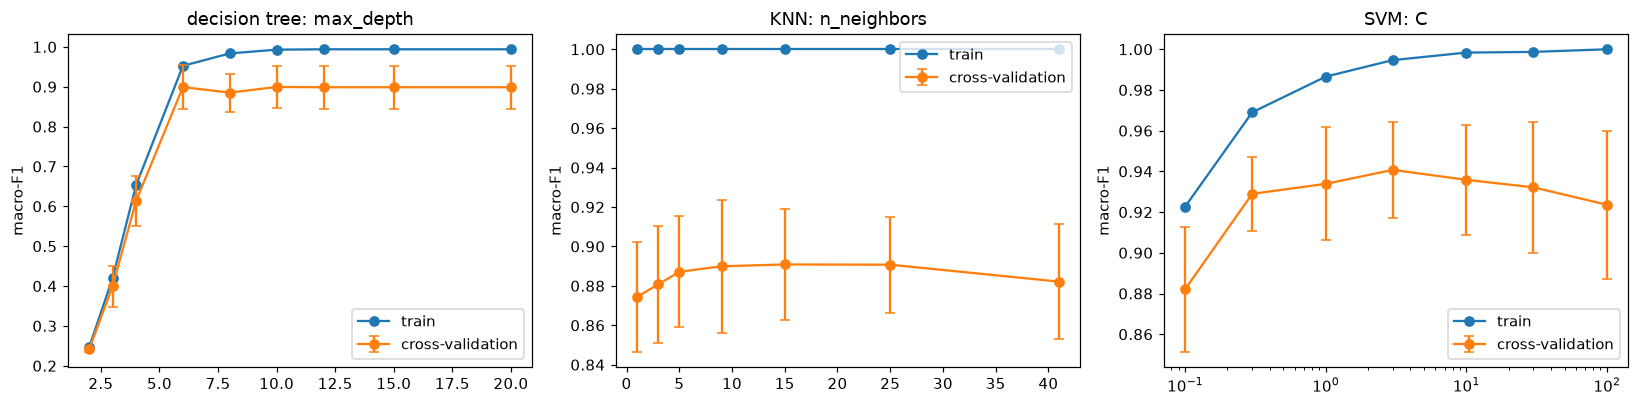

decision tree: max_depth   best value = 10     CV macro-F1 = 0.899  (train 0.993)
KNN: n_neighbors           best value = 15     CV macro-F1 = 0.891  (train 1.000)
SVM: C                     best value = 3      CV macro-F1 = 0.941  (train 0.995)


In [20]:
def sweep(make_model, values):
    out = []
    for v in values:
        r = evaluate(make_model(v))
        out.append((v, r["train_macro_f1"].mean(), r["test_macro_f1"].mean(), r["test_macro_f1"].std()))
    return pd.DataFrame(out, columns=["value", "train", "cv", "cv_sd"])

sweeps = {
    "decision tree: max_depth": sweep(lambda d: DecisionTreeClassifier(max_depth=d, min_samples_leaf=3, random_state=RANDOM_STATE), [2, 3, 4, 6, 8, 10, 12, 15, 20]),
    "KNN: n_neighbors": sweep(lambda k: KNeighborsClassifier(n_neighbors=k, weights="distance"), [1, 3, 5, 9, 15, 25, 41]),
    "SVM: C": sweep(lambda c: SVC(C=c, gamma="scale"), [0.1, 0.3, 1, 3, 10, 30, 100]),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, s) in zip(axes, sweeps.items()):
    ax.plot(s["value"], s["train"], "o-", label="train")
    ax.errorbar(s["value"], s["cv"], yerr=s["cv_sd"], fmt="o-", capsize=3, label="cross-validation")
    if "SVM" in title: ax.set_xscale("log")
    ax.set_title(title); ax.set_ylabel("macro-F1"); ax.legend()
plt.tight_layout(); plt.show()
best = {t: s.loc[s["cv"].idxmax()] for t, s in sweeps.items()}
for t, b in best.items():
    print(f"{t:26s} best value = {b['value']:<6g} CV macro-F1 = {b['cv']:.3f}  (train {b['train']:.3f})")

### 3.6 Fair comparison of the tuned models
Same training rows, same five grouped folds, same metric for every model.

,CV macro-F1,sd,CV accuracy,train macro-F1
model,,,,
dummy (most frequent),0.033,0.001,0.176,0.033
dummy (stratified),0.113,0.005,0.132,0.106
decision tree (depth 10),0.899,0.053,0.906,0.993
"KNN (k = 15, distance)",0.891,0.028,0.908,1.000
"SVM (RBF, C = 3)",0.941,0.024,0.948,0.995


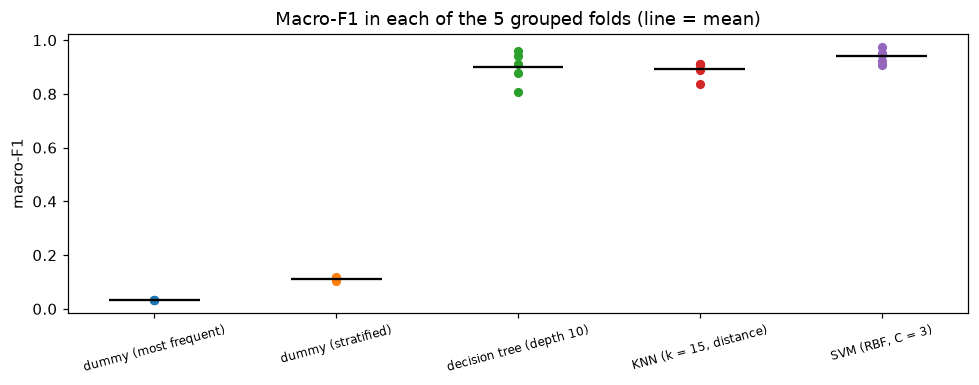

In [21]:
best_depth = int(best["decision tree: max_depth"]["value"])
best_k = int(best["KNN: n_neighbors"]["value"])
best_c = float(best["SVM: C"]["value"])
final_models = {
    "dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    f"decision tree (depth {best_depth})": DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=3, random_state=RANDOM_STATE),
    f"KNN (k = {best_k}, distance)": KNeighborsClassifier(n_neighbors=best_k, weights="distance"),
    f"SVM (RBF, C = {best_c:g})": SVC(C=best_c, gamma="scale"),
}
results, folds = [], {}
for name, model in final_models.items():
    r = evaluate(model)
    folds[name] = r["test_macro_f1"]
    results.append({"model": name, "CV macro-F1": r["test_macro_f1"].mean(), "sd": r["test_macro_f1"].std(),
                    "CV accuracy": r["test_accuracy"].mean(), "train macro-F1": r["train_macro_f1"].mean()})
results = pd.DataFrame(results).set_index("model")
display(results.round(3))

fold_df = pd.DataFrame(folds, index=[f"fold {i+1}" for i in range(5)])
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, name in enumerate(fold_df.columns):
    ax.scatter([i] * 5, fold_df[name], s=25)
    ax.hlines(fold_df[name].mean(), i - 0.25, i + 0.25, color="black")
ax.set_xticks(range(len(fold_df.columns))); ax.set_xticklabels(fold_df.columns, rotation=15, fontsize=8)
ax.set_ylabel("macro-F1"); ax.set_title("Macro-F1 in each of the 5 grouped folds (line = mean)")
plt.tight_layout(); plt.show()

In [22]:
model_names = [n for n in final_models if not n.startswith("dummy")]
best_name = results.loc[model_names, "CV macro-F1"].idxmax()
print("Best model in cross-validation:", best_name)
print("Beats the most-frequent dummy in every fold:",
      {n: bool((folds[n] > folds["dummy (most frequent)"]).all()) for n in model_names})
print("Beats the stratified dummy in every fold:",
      {n: bool((folds[n] > folds["dummy (stratified)"]).all()) for n in model_names})

Best model in cross-validation: SVM (RBF, C = 3)
Beats the most-frequent dummy in every fold: {'decision tree (depth 10)': True, 'KNN (k = 15, distance)': True, 'SVM (RBF, C = 3)': True}
Beats the stratified dummy in every fold: {'decision tree (depth 10)': True, 'KNN (k = 15, distance)': True, 'SVM (RBF, C = 3)': True}


## 4. Results and error analysis

### 4.1 Which types does the best model mix up? (cross-validated predictions on training rows)
`cross_val_predict` gives every training row a prediction from a model that did **not** see that row's series.

In [23]:
best_model = final_models[best_name]
oof = cross_val_predict(make_pipeline(best_model), X_train, y_train, groups=g_train, cv=cv)
print(classification_report(y_train, oof, labels=TYPES, digits=3))

                  precision    recall  f1-score   support

            sofa      0.994     0.982     0.988       340
        armchair      0.993     0.989     0.991       273
           chair      0.953     0.996     0.974       247
             bed      1.000     0.987     0.993       527
        wardrobe      1.000     0.975     0.987       559
chest_of_drawers      0.911     0.901     0.906       523
            desk      0.890     0.894     0.892       254
    coffee_table      0.854     0.918     0.885       134
        tv_stand      0.832     0.859     0.845       311

        accuracy                          0.948      3168
       macro avg      0.936     0.944     0.940      3168
    weighted avg      0.949     0.948     0.948      3168



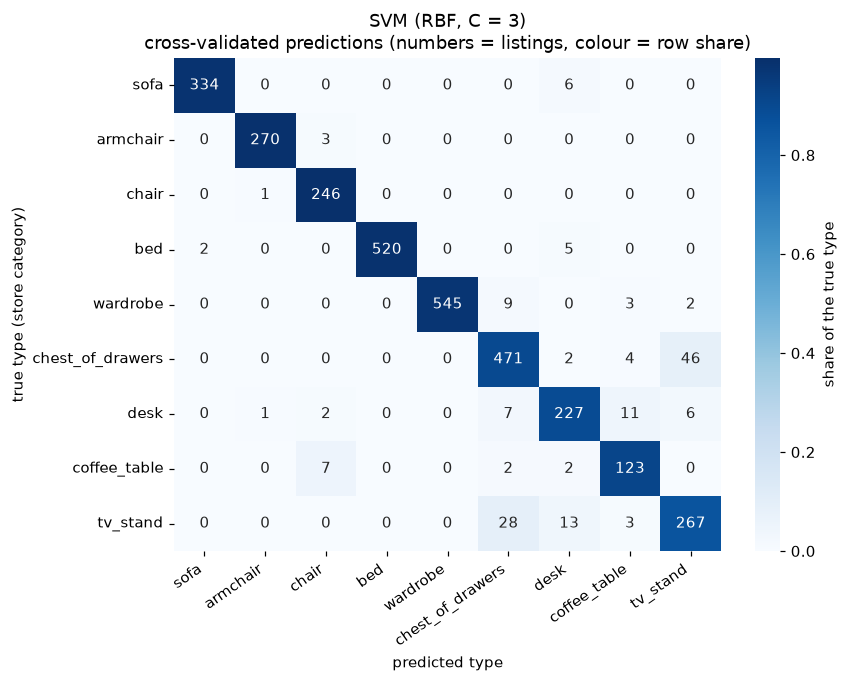

In [24]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=TYPES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(8, 6.3))
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=TYPES, yticklabels=TYPES,
                cbar_kws={"label": "share of the true type"})
    plt.xlabel("predicted type"); plt.ylabel("true type (store category)"); plt.title(title)
    plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
    return cm

cm_oof = plot_confusion(y_train, oof, f"{best_name}\ncross-validated predictions (numbers = listings, colour = row share)")

In [25]:
# The most frequent mix-ups
cm_df = pd.DataFrame(cm_oof, index=TYPES, columns=TYPES)
pairs = cm_df.stack().rename("n").reset_index()
pairs.columns = ["true", "predicted", "n"]
pairs = pairs[pairs["true"] != pairs["predicted"]].sort_values("n", ascending=False)
pairs["share of true type"] = (pairs["n"] / pairs["true"].map(cm_df.sum(axis=1))).round(3)
pairs.head(10).reset_index(drop=True)

,true,predicted,n,share of true type
0,chest_of_drawers,tv_stand,46,0.088
1,tv_stand,chest_of_drawers,28,0.090
2,tv_stand,desk,13,0.042
3,desk,coffee_table,11,0.043
4,wardrobe,chest_of_drawers,9,0.016
5,desk,chest_of_drawers,7,0.028
6,coffee_table,chair,7,0.052
7,sofa,desk,6,0.018
8,desk,tv_stand,6,0.024
9,bed,desk,5,0.009


In [26]:
# What do the confused listings look like? Medians for the four biggest mix-ups.
train_view = df.iloc[train_idx].assign(predicted=oof)
show = ["width_cm", "depth_cm", "height_cm", "price_kzt"]
for _, p in pairs.head(4).iterrows():
    t, pr = p["true"], p["predicted"]
    tab = pd.DataFrame({
        f"{t}, predicted correctly": train_view.loc[(train_view.furniture_type == t) & (train_view.predicted == t), show].median(),
        f"{t}, predicted as {pr}": train_view.loc[(train_view.furniture_type == t) & (train_view.predicted == pr), show].median(),
        f"{pr}, all listings": train_view.loc[train_view.furniture_type == pr, show].median(),
    }).T.round(0)
    print(f"--- {t} -> {pr}: {p['n']} listings ---"); display(tab)

--- chest_of_drawers -> tv_stand: 46 listings ---


,width_cm,depth_cm,height_cm,price_kzt
"chest_of_drawers, predicted correctly",113.0,42.0,90.0,214300.0
"chest_of_drawers, predicted as tv_stand",146.0,40.0,70.0,183670.0
"tv_stand, all listings",160.0,40.0,56.0,162240.0


--- tv_stand -> chest_of_drawers: 28 listings ---


,width_cm,depth_cm,height_cm,price_kzt
"tv_stand, predicted correctly",160.0,40.0,55.0,162240.0
"tv_stand, predicted as chest_of_drawers",137.0,42.0,56.0,145390.0
"chest_of_drawers, all listings",115.0,42.0,88.0,206640.0


--- tv_stand -> desk: 13 listings ---


,width_cm,depth_cm,height_cm,price_kzt
"tv_stand, predicted correctly",160.0,40.0,55.0,162240.0
"tv_stand, predicted as desk",250.0,50.0,78.0,229610.0
"desk, all listings",120.0,60.0,76.0,160700.0


--- desk -> coffee_table: 11 listings ---


,width_cm,depth_cm,height_cm,price_kzt
"desk, predicted correctly",120.0,60.0,76.0,160700.0
"desk, predicted as coffee_table",40.0,50.0,49.0,68830.0
"coffee_table, all listings",50.0,45.0,45.0,99460.0


In [27]:
# Concrete examples of the two biggest mix-ups (names shown only to explain errors, never used by the model)
cols = ["name", "site_category", "width_cm", "depth_cm", "height_cm", "price_kzt", "materials", "predicted"]
for _, p in pairs.head(2).iterrows():
    sub = train_view[(train_view.furniture_type == p["true"]) & (train_view.predicted == p["predicted"])]
    print(f"--- true {p['true']}, predicted {p['predicted']} ---")
    display(sub[cols].sample(min(6, len(sub)), random_state=RANDOM_STATE))

--- true chest_of_drawers, predicted tv_stand ---


,name,site_category,width_cm,depth_cm,height_cm,price_kzt,materials,predicted
3502,Тумба Шелтон 148x64 Латте,Комоды,148.0,46.0,64.0,206640.0,chipboard|mdf|metal|plastic,tv_stand
3373,Тумба Ханна 140x80 Белый,Комоды,140.0,42.0,80.0,137740.0,chipboard|solid_wood,tv_stand
3397,Тумба Кимбол 150x70 Черный,Комоды,150.0,43.0,70.0,183670.0,chipboard|mdf,tv_stand
3551,Тумба Торвалль 115x81 Белый,Комоды,115.0,40.0,81.0,122420.0,chipboard|solid_wood,tv_stand
3485,Тумба подвесная Сайрис 98x25 Дуб Барбера,Комоды,98.0,35.0,25.0,68830.0,chipboard|metal,tv_stand
3504,Тумба Шелтон 148x64 Светло-бежевый,Комоды,148.0,46.0,64.0,206640.0,chipboard|mdf|metal|plastic,tv_stand


--- true tv_stand, predicted chest_of_drawers ---


,name,site_category,width_cm,depth_cm,height_cm,price_kzt,materials,predicted
3346,Тумба для винила Янсен 90x75 Графитовый,Тумбы под телевизор,90.0,40.0,75.0,114770.0,chipboard|solid_wood,chest_of_drawers
3708,ТВ-тумба Кейлет 182x56 Штриx Графитовый,Тумбы под телевизор,182.0,42.0,56.0,191330.0,chipboard|mdf|plastic,chest_of_drawers
3345,Тумба для винила Янсен 55x75 Белый,Тумбы под телевизор,55.0,40.0,75.0,91800.0,chipboard|solid_wood,chest_of_drawers
3704,ТВ-тумба Кейлет 182x56 Штрих Оливковый,Тумбы под телевизор,182.0,42.0,56.0,176020.0,chipboard|mdf|plastic,chest_of_drawers
3337,Тумба для винила Лемос 1-91x46 Графитовый,Тумбы под телевизор,91.0,40.0,46.0,76490.0,chipboard|solid_wood,chest_of_drawers
3695,ТВ-тумба Кейлет 137x56 Арка Графитовый,Тумбы под телевизор,137.0,42.0,56.0,145390.0,chipboard|mdf|plastic,chest_of_drawers


**Where the model fails, and why**
* **Most errors are one pair: chest of drawers vs TV stand.** 46 chests were predicted as TV stands and 28 TV stands as chests: 74 of the roughly 165 cross-validated errors.
* **The chests called "TV stand" are low and wide.** Their median is 146x40x70 cm, against 113x42x90 cm for chests that were recognised. In shape, that is a TV stand.
* **Their names show it is the store's labelling, not only the model.** "Тумба Шелтон 148x64", "Тумба Кимбол 150x70" and "Тумба Ханна 140x80": the store itself calls them *тумба* (a low cabinet) but files them under "Комоды". Section 2.3 showed that only 60% of the listings labelled chest of drawers have "комод" in their name. Part of these errors is a fuzzy category boundary in the labels, not a model failure. A 150x45x65 cm cabinet can honestly be either type.
* **The opposite direction:** TV stands predicted as chests are taller cabinets, such as the "Тумба для винила" (vinyl record cabinet, 75 cm high), or sit right on the boundary in height (56 cm) and width.
* **TV stand -> desk:** very wide (median 250 cm) and tall (78 cm) media units.
* **Desk -> coffee table:** small children's desks (median 40x50x49 cm).
* **Strong classes:** beds, wardrobes, sofas and armchairs are recognised with F1 >= 0.99, because their shapes are distinctive. The question's example pair, wardrobe vs chest of drawers, is rarely confused: only 9 of 559 wardrobes were predicted as chests.

### 4.2 Which specifications separate the types?
A shallow decision tree shows the rules in a readable way. The feature importances of the tuned tree show which inputs it relies on most.

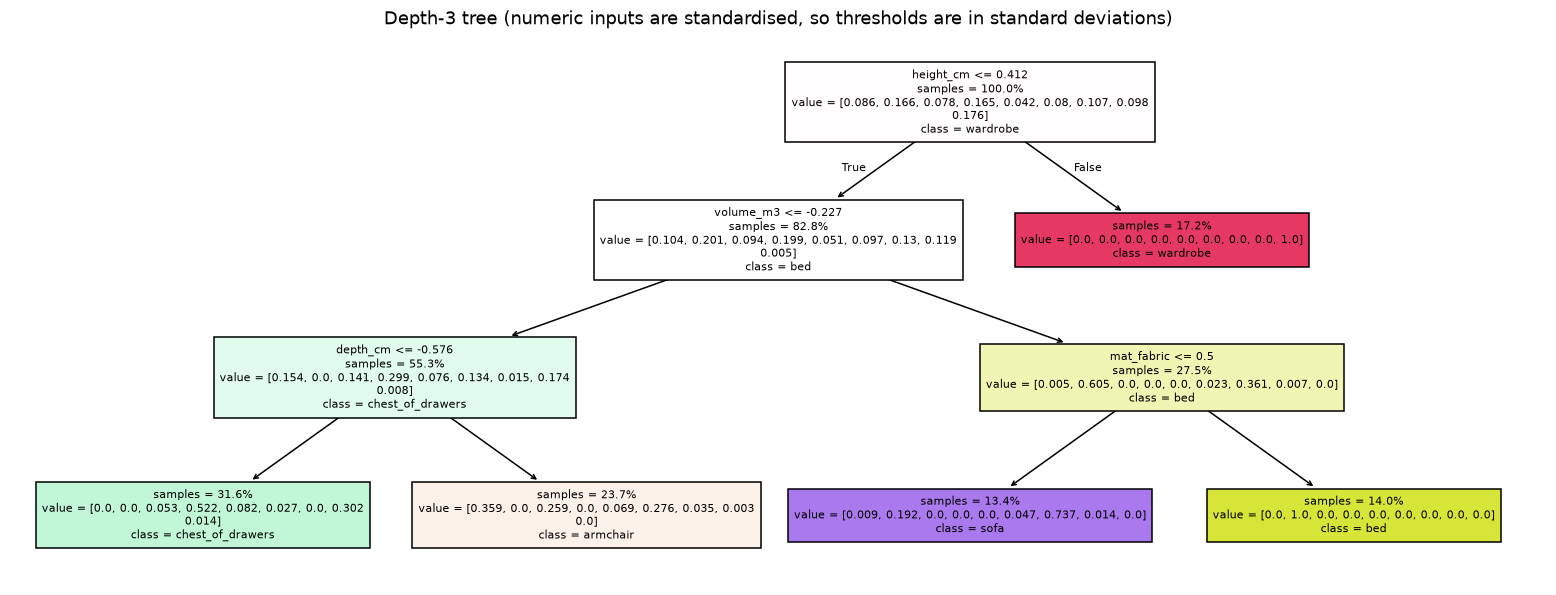

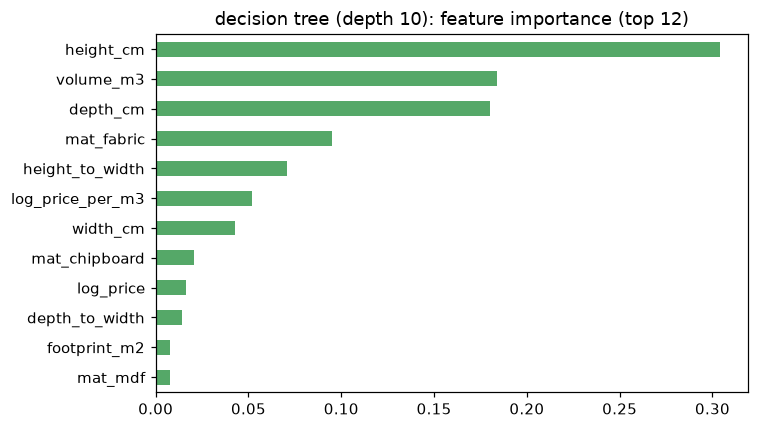

In [28]:
small_tree = make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)).fit(X_train, y_train)
names = [n.split("__", 1)[1] for n in small_tree.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(18, 6.5))
plot_tree(small_tree.named_steps["model"], feature_names=names, class_names=small_tree.named_steps["model"].classes_,
          filled=True, impurity=False, proportion=True, fontsize=7)
plt.title("Depth-3 tree (numeric inputs are standardised, so thresholds are in standard deviations)"); plt.show()

tree_name = [n for n in final_models if n.startswith("decision")][0]
tuned_tree = make_pipeline(final_models[tree_name]).fit(X_train, y_train)
imp = pd.Series(tuned_tree.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot.barh(figsize=(7, 4), title=f"{tree_name}: feature importance (top 12)", color="#55A868")
plt.tight_layout(); plt.show()

In [29]:
# How much does each group of inputs add? (best model type, grouped CV on training rows)
SIZES = ["width_cm", "depth_cm", "height_cm", "footprint_m2", "volume_m3", "height_to_width", "depth_to_width"]
input_sets = {
    "sizes only": (SIZES, [], []),
    "sizes + price": (NUMERIC, [], []),
    "sizes + price + materials": (NUMERIC, MATERIALS, []),
    "all (+ colour)": (NUMERIC, MATERIALS, COLOUR),
}
abl = []
for label, (num, mats, colr) in input_sets.items():
    parts = [("numeric", StandardScaler(), num)]
    if mats: parts.append(("materials", "passthrough", mats))
    if colr: parts.append(("colour", OneHotEncoder(handle_unknown="ignore", min_frequency=10), colr))
    pipe = Pipeline([("prep", ColumnTransformer(parts)), ("model", best_model)])
    r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv, scoring="f1_macro")
    abl.append({"inputs": label, "CV macro-F1": r["test_score"].mean(), "sd": r["test_score"].std()})
pd.DataFrame(abl).set_index("inputs").round(3)

,CV macro-F1,sd
inputs,,
sizes only,0.862,0.031
sizes + price,0.914,0.028
sizes + price + materials,0.945,0.026
all (+ colour),0.941,0.024


**Which specifications do the work**
* **The depth-3 tree reads like a catalogue rule.** First it asks about *height*: everything tall is a wardrobe (that leaf is 100% wardrobes). Then it asks about *volume*: big items are beds or sofas, split by the fabric flag. Then *depth*: shallow items form the chest / TV stand / desk group.
* **The tuned tree relies most on** height, volume and depth, then the fabric flag, the height/width ratio and price per m³.
* **What each group of inputs adds:**
  * sizes alone already give macro-F1 0.862;
  * adding price raises it to 0.914;
  * adding materials raises it to 0.945 (partly the store's form habits, see 2.4);
  * colour adds nothing (0.941).

  The answer to the question comes mostly from **dimensions and price**, and colour could be dropped.

### 4.3 Decide, then open the test set once
We chose the model with cross-validation only. Now we fit it on all training rows and score it **once** on the held-out test series, next to the dummy baseline.

In [30]:
final = make_pipeline(best_model).fit(X_train, y_train)
test_pred = final.predict(X_test)
dummy_pred = make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train).predict(X_test)
print(f"{best_name}:  test macro-F1 = {f1_score(y_test, test_pred, average='macro'):.3f}   accuracy = {accuracy_score(y_test, test_pred):.3f}")
print(f"dummy (most frequent):  test macro-F1 = {f1_score(y_test, dummy_pred, average='macro'):.3f}   accuracy = {accuracy_score(y_test, dummy_pred):.3f}")
print()
print(classification_report(y_test, test_pred, labels=TYPES, digits=3))

SVM (RBF, C = 3):  test macro-F1 = 0.978   accuracy = 0.979
dummy (most frequent):  test macro-F1 = 0.033   accuracy = 0.177

                  precision    recall  f1-score   support

            sofa      0.977     1.000     0.988        85
        armchair      1.000     0.942     0.970        69
           chair      0.939     1.000     0.969        62
             bed      1.000     0.985     0.992       132
        wardrobe      0.979     1.000     0.989       140
chest_of_drawers      0.984     0.953     0.969       129
            desk      1.000     0.922     0.959        64
    coffee_table      1.000     1.000     1.000        34
        tv_stand      0.929     1.000     0.963        78

        accuracy                          0.979       793
       macro avg      0.979     0.978     0.978       793
    weighted avg      0.979     0.979     0.979       793



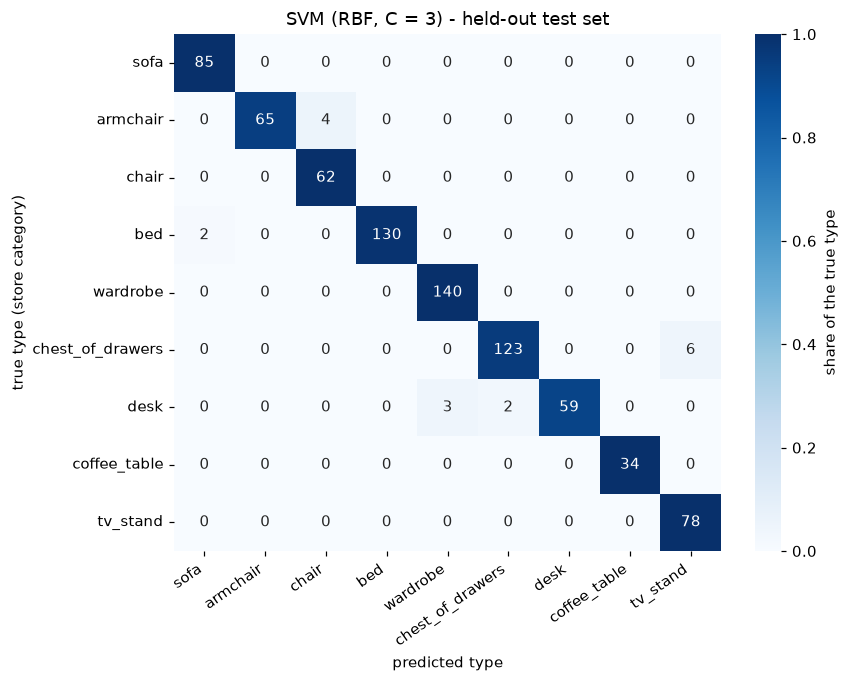

In [31]:
cm_test = plot_confusion(y_test, test_pred, f"{best_name} - held-out test set")

In [32]:
# Used as a catalogue check: the listings where the model disagrees with the store category
flagged = test_pred != y_test.values
print(f"test listings where the model disagrees with the store category: {flagged.sum()} of {len(y_test)} ({flagged.mean():.1%})")
test_view = df.iloc[test_idx].assign(predicted=test_pred)
test_view.loc[flagged, ["name", "furniture_type", "predicted", "width_cm", "depth_cm", "height_cm", "price_kzt"]].sample(
    min(10, int(flagged.sum())), random_state=RANDOM_STATE)

test listings where the model disagrees with the store category: 17 of 793 (2.1%)


,name,furniture_type,predicted,width_cm,depth_cm,height_cm,price_kzt
1034,Кресло Акапулько Бежевый-Синий/Черный,armchair,chair,66.0,66.0,83.0,38210.0
1035,Кресло Акапулько Бежевый-Бордовый/Черный,armchair,chair,66.0,66.0,83.0,38210.0
1727,Кровать Леос 160 Молочный,bed,sofa,210.0,170.0,94.0,421010.0
3592,Тумба Воямполь 150x64 Серо-зеленый,chest_of_drawers,tv_stand,150.0,35.0,64.0,153050.0
3353,Тумба Енссон 148x64 Оливковый,chest_of_drawers,tv_stand,148.0,46.0,64.0,185970.0
3591,Тумба Воямполь 150x64 Латте,chest_of_drawers,tv_stand,150.0,35.0,64.0,153050.0
2186,Письменный стол Пенни 132x55 Латте,desk,wardrobe,132.0,55.0,190.0,214300.0
3590,Тумба Воямполь 150x64 Графитовый,chest_of_drawers,tv_stand,150.0,35.0,64.0,153050.0
1036,Кресло Акапулько Бежевый-Оливковый/Черный,armchair,chair,66.0,66.0,83.0,38210.0
2187,Письменный стол Пенни 132x55 Серо-зеленый,desk,wardrobe,132.0,55.0,190.0,214300.0


**Test result.** The SVM reaches **macro-F1 0.978** (accuracy 0.979) on the 793 held-out listings from 103 unseen series. The dummy reaches 0.033.
* **Why the test score is higher than cross-validation (0.941 ± 0.024).** This test set is one grouped split, and its series turned out a little easier. The cross-validated 0.94 is the more careful estimate of what to expect on new listings.
* **The 17 disagreements are exactly the kind of listing a catalogue checker should show to a human:**
  * "Тумба Воямполь 150x64" and "Тумба Енссон 148x64", filed as chests but shaped like TV stands (the same ambiguity as above);
  * "Кресло Акапулько", a 66 cm wide, 38,000 ₸ armchair, which has the size and price of a chair;
  * "Письменный стол Пенни", a desk with a 190 cm shelving tower, which has the height of a wardrobe.

## 5. Conclusions and limitations

**Answer to the question.** Yes. From width, depth, height, price, materials and colour alone, the type of a mebel.kz listing can be predicted for the nine types.
* **Score.** The tuned SVM reaches a macro-F1 of **0.94** in cross-validation grouped by series, and **0.98** on the held-out test set. The dummy baselines score 0.03 (most frequent) and 0.11 (stratified).
* **All three Week 4 models beat both dummies in every fold:** decision tree 0.90, KNN 0.89, SVM 0.94.
* **Inputs.** Dimensions alone give 0.86. Price adds about 5 points and materials about 3. Colour adds nothing.

**Which specifications separate similar types**
* **Wardrobe vs chest of drawers:** height (median 212 vs 87 cm). Almost never confused (9 of 559 wardrobes).
* **Chair vs armchair vs sofa:** width, depth and price.
* **Desk vs coffee table vs TV stand:** height (76 / 43 / 54 cm) and depth.
* **The real weak spot is chest of drawers vs TV stand.** They have the same depth and materials and only a different typical height, and the store itself files some low cabinets (*тумба*) as chests. These errors are as much about where to draw the category line as about the model.

**For a marketplace.** The model's disagreement with the seller's category works as a flag. On the test set it flagged 2% of listings, and the flagged items are mostly genuinely borderline ones worth a human look.

**Limitations**
* **No weight.** mebel.kz does not publish it, so one of the features named in the task is missing.
* **One store, one city, mostly one brand.** Other marketplaces' sellers may enter sizes in a different order (width and depth swapped) or in other units. Before using the model elsewhere, orientation-free features (for example sorted dimensions) and data from a second store would be needed.
* **Labels are the store's own categories.** They are mostly right but fuzzy at the chest / TV-stand border, so some "errors" are label noise. We have no hand-checked ground truth.
* **Material flags partly mirror the store's form templates** (for example, where fabric is recorded). They may not transfer to other sites.
* **Only 512 distinct series.** The 3,961 rows contain many colour variants, so the variety of designs is smaller than the row count suggests. Grouped CV handles this in the evaluation, but it limits what the model has seen.
* **3,961 rows**, slightly below the 4,000 "ideal" target (the minimum is 2,000). We sampled at most 700 pages per type. A later top-up stopped because the site started answering with HTTP 500 errors, and we did not keep retrying.
* **One price snapshot** (7 October 2026, KZT, including that day's discounts).
* **One test split.** Fold-to-fold variation in CV is about ±0.02.

**Next steps**
* Collect the product photos (their URLs are already in the JSON-LD block) and compare an image model with this specification model.
* Add a second store (lifedeco.kz) to test whether the rules transfer.
* Ask a person to re-label the borderline chest / TV-stand listings.

## 6. Contributions and AI tools

## Who did what

| Part of the project | Sultanbek Zhumagaliev | Tamerlan Yessimov |
|---|---|---|
| Choosing the question and the source (mebel.kz) | shared | shared |
| First scraping prototype (sitemap reading, `main.py`, `part1.py`) | ✓ | ✓ |
| Checking the source: robots.txt, comparing scraped rows with the live pages | | ✓ |
| Running the full collection (`scraper/collect_mebel.py`) and keeping the raw data and log | ✓ | |
| Building the clean table and the category mapping (`scraper/build_dataset.py`) | ✓ | |
| Data card (`DATA_CARD.md`) and data ethics section | | ✓ |
| Cleaning and leakage check (notebook section 2.1-2.3) | ✓ | |
| Exploration and feature ideas (section 2.4) | | ✓ |
| Modelling: split, pipeline, baseline, tree / KNN / SVM, cross-validation (section 3) | ✓ | |
| Error analysis and confusion matrix (section 4) | | ✓ |
| Conclusions and limitations (section 5) | shared | shared |
| Reviewing the notebook, re-running it top to bottom | shared | shared |

## AI tools we used

| Tool | What we used it for |
|---|---|
| **Claude Code** (Anthropic, model Claude Opus 5.5), in the terminal | Inspected the structure of mebel.kz pages (JSON-LD, spec table, sitemap) and wrote the scraper `scraper/collect_mebel.py` (rate limiting, resumable runs, logging). Wrote `scraper/build_dataset.py` (category-to-type mapping, material and colour normalisation). Drafted the analysis notebook `furniture_classification.ipynb` (cleaning checks, leakage checks, pipelines, cross-validation, confusion-matrix analysis), and drafted this file, `DATA_CARD.md` and `README.md`. |

How we used the AI output: we ran every script ourselves and checked scraped rows against the live product pages. We re-ran the notebook from top to bottom and read every output before writing our interpretation. We are responsible for every claim in the notebook. The modelling methods are the ones from the Week 3-4 course notebooks (`week3-4/`).